# 01. Data Profiling: Sales Performance Dashboard

Notebook kiểm tra và khám phá bộ dữ liệu `Sales_Raw_data.csv` trước khi đưa vào Power BI. Mục tiêu:

1. Hiểu cấu trúc dữ liệu (số dòng, số cột, kiểu dữ liệu, khoảng thời gian).
2. Kiểm tra chất lượng: giá trị trống, trùng lặp, định dạng mã, giá trị ngoài miền.
3. Kiểm tra các quy tắc nghiệp vụ (Revenue, Cost, Profit, trạng thái đơn, rating).
4. Khám phá nhanh phân bố theo thời gian, sản phẩm, khách hàng, hủy đơn.
5. Đối soát các con số chính với dashboard Power BI.

**Cách chạy:** đặt file CSV tại `data/raw/Sales_Raw_data.csv`, mở notebook từ thư mục `eda/`, chọn *Restart & Run All*. Yêu cầu: `pandas`, `numpy`, `matplotlib`.

Kết luận tổng hợp nằm ở [`eda_findings.md`](./eda_findings.md).

## 1. Thiết lập và nạp dữ liệu

In [ ]:
from pathlib import Path
import re

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 140)
pd.set_option("display.float_format", lambda x: f"{x:,.2f}")
plt.rcParams.update({"figure.dpi": 100, "axes.spines.top": False, "axes.spines.right": False})

CSV_PATH = Path("../data/raw/Sales_Raw_data.csv")

df = pd.read_csv(CSV_PATH, encoding="utf-8")
df["OrderDate"] = pd.to_datetime(df["OrderDate"])

print(f"Loaded {len(df):,} rows x {df.shape[1]} columns from {CSV_PATH.name}")

Loaded 20,000 rows x 21 columns from Sales_Performance_Raw_data.csv


## 2. Cấu trúc dữ liệu

In [2]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 20000 entries, 0 to 19999
Data columns (total 21 columns):
 #   Column              Non-Null Count  Dtype         
---  ------              --------------  -----         
 0   OrderID             20000 non-null  str           
 1   OrderDate           20000 non-null  datetime64[us]
 2   CustomerID          20000 non-null  str           
 3   Gender              20000 non-null  str           
 4   AgeGroup            20000 non-null  str           
 5   Loyalty             20000 non-null  str           
 6   ProductID           20000 non-null  str           
 7   SKU                 20000 non-null  str           
 8   ProductType         20000 non-null  str           
 9   ProductName         20000 non-null  str           
 10  Quantity            20000 non-null  int64         
 11  UnitPrice           20000 non-null  float64       
 12  UnitCost            20000 non-null  float64       
 13  Revenue             20000 non-null  float64       
 14  C

In [3]:
df.head()

,OrderID,OrderDate,CustomerID,Gender,AgeGroup,Loyalty,ProductID,SKU,ProductType,ProductName,Quantity,UnitPrice,UnitCost,Revenue,Cost,Profit,OrderStatus,ShippingType,PaymentType,Rating,CancellationReason
0,ORD000001,2023-09-07,C05318,Female,Senior,No,P0006,TAB-0006,Tablet,Tablet Model C,2,144.85,36.36,289.70,72.72,216.98,Cancelled,Standard,E-Wallet,NaN,Changed mind
1,ORD000002,2023-09-19,C08049,Female,Middle Age,No,P0001,SMA-0001,Smartphone,Smartphone Model A,2,610.99,124.85,"1,221.98",249.70,972.28,Completed,Standard,Debit Card,3.00,NaN
2,ORD000003,2023-09-26,C07587,Male,Adult,Yes,P0006,TAB-0006,Tablet,Tablet Model C,5,144.85,36.36,724.25,181.80,542.45,Completed,Standard,Bank Transfer,3.00,NaN
3,ORD000004,2023-09-25,C09403,Male,Middle Age,No,P0012,LAP-0012,Laptop,Laptop Model B,3,831.04,215.39,"2,493.12",646.17,"1,846.95",Completed,Express,Bank Transfer,4.00,NaN
4,ORD000005,2023-09-07,C10329,Male,Middle Age,Yes,P0001,SMA-0001,Smartphone,Smartphone Model A,6,610.99,124.85,"3,665.94",749.10,"2,916.84",Completed,Standard,Credit Card,3.00,NaN


## 3. Chất lượng dữ liệu

### 3.1 Giá trị trống

In [4]:
missing = df.isna().sum().rename("missing").to_frame()
missing["pct"] = (missing["missing"] / len(df) * 100).round(2)
missing[missing["missing"] > 0]

,missing,pct
Rating,6565,32.82
CancellationReason,13435,67.18


`Rating` và `CancellationReason` có giá trị trống. Kiểm tra xem chúng có trống đúng theo logic nghiệp vụ không: đơn bị hủy không có đánh giá, đơn hoàn thành không có lý do hủy.

In [5]:
pd.crosstab(
    df["OrderStatus"],
    [df["Rating"].isna().rename("Rating is blank"), df["CancellationReason"].isna().rename("Reason is blank")],
)

Rating is blank,False,True
Reason is blank,True,False
OrderStatus,,
Cancelled,0,6565
Completed,13435,0


### 3.2 Trùng lặp và khoảng trắng thừa

In [6]:
print("Fully duplicated rows :", df.duplicated().sum())
print("Duplicated OrderID    :", df["OrderID"].duplicated().sum())

text_cols = [c for c in df.columns if pd.api.types.is_string_dtype(df[c])]
padded = {c: int((df[c].dropna() != df[c].dropna().str.strip()).sum()) for c in text_cols}
print("Text columns with leading/trailing spaces:", {k: v for k, v in padded.items() if v} or "none")

Fully duplicated rows : 0
Duplicated OrderID    : 0
Text columns with leading/trailing spaces: none


## 4. Toàn vẹn dữ liệu và quy tắc nghiệp vụ

Mỗi kiểm tra trả về `passed = True/False`. Tất cả phải đạt trước khi tách bảng chiều trong Power Query.

In [7]:
checks = []
def add(name, passed, detail=""):
    checks.append({"check": name, "passed": bool(passed), "detail": detail})

# --- Keys and formats ---
add("OrderID is unique", df["OrderID"].is_unique)
add("OrderID format ORD + 6 digits", df["OrderID"].str.fullmatch(r"ORD\d{6}").all())
add("CustomerID format C + 5 digits", df["CustomerID"].str.fullmatch(r"C\d{5}").all())
add("ProductID format P + 4 digits", df["ProductID"].str.fullmatch(r"P\d{4}").all())
add("SKU format AAA-0000", df["SKU"].str.fullmatch(r"[A-Z]{3}-\d{4}").all())

# --- Nulls ---
required = [c for c in df.columns if c not in ("Rating", "CancellationReason")]
add("No nulls outside Rating / CancellationReason", df[required].notna().all().all())

# --- Product mapping ---
prod_cols = ["SKU", "ProductType", "ProductName", "UnitPrice", "UnitCost"]
add("Each ProductID maps to exactly one SKU/type/name/price/cost",
    (df.groupby("ProductID")[prod_cols].nunique() == 1).all().all())
add("ProductID <-> SKU is 1-to-1",
    df["ProductID"].nunique() == df["SKU"].nunique() == df[["ProductID", "SKU"]].drop_duplicates().shape[0])

# --- Customer attributes (needed to build dim_customer with Table.Distinct on CustomerID) ---
cust_nunique = df.groupby("CustomerID")[["Gender", "AgeGroup", "Loyalty"]].nunique()
add("Gender / AgeGroup / Loyalty constant within each CustomerID", (cust_nunique == 1).all().all(),
    f"customers with >1 value: {int((cust_nunique > 1).any(axis=1).sum())}")

# --- Value ranges ---
add("Quantity >= 1", (df["Quantity"] >= 1).all(), f"range {df['Quantity'].min()}-{df['Quantity'].max()}")
add("UnitPrice > UnitCost > 0", ((df["UnitPrice"] > df["UnitCost"]) & (df["UnitCost"] > 0)).all())
add("Profit > 0 for every order", (df["Profit"] > 0).all(), f"min profit {df['Profit'].min():,.2f}")
add("Rating within 1-5", df["Rating"].dropna().between(1, 5).all())
add("OrderStatus in {Completed, Cancelled}", df["OrderStatus"].isin(["Completed", "Cancelled"]).all())

# --- Financial identities (tolerance 0.011 for 2-decimal rounding) ---
tol = 0.011
add("Revenue = Quantity x UnitPrice", np.isclose(df["Revenue"], df["Quantity"] * df["UnitPrice"], atol=tol).all())
add("Cost = Quantity x UnitCost", np.isclose(df["Cost"], df["Quantity"] * df["UnitCost"], atol=tol).all())
add("Profit = Revenue - Cost", np.isclose(df["Profit"], df["Revenue"] - df["Cost"], atol=tol).all())

# --- Status logic ---
is_cancel = df["OrderStatus"] == "Cancelled"
add("Rating is blank if and only if order is Cancelled", (df["Rating"].isna() == is_cancel).all())
add("CancellationReason is filled if and only if order is Cancelled", (df["CancellationReason"].notna() == is_cancel).all())

# --- Dates ---
add("OrderDate has no nulls and is a valid date", df["OrderDate"].notna().all(),
    f"{df['OrderDate'].min():%Y-%m-%d} to {df['OrderDate'].max():%Y-%m-%d}")

result = pd.DataFrame(checks)
result.index += 1
print(f"{result['passed'].sum()} / {len(result)} checks passed")
result

20 / 20 checks passed


,check,passed,detail
1,OrderID is unique,True,
2,OrderID format ORD + 6 digits,True,
3,CustomerID format C + 5 digits,True,
4,ProductID format P + 4 digits,True,
5,SKU format AAA-0000,True,
6,No nulls outside Rating / CancellationReason,True,
7,Each ProductID maps to exactly one SKU/type/na...,True,
8,ProductID <-> SKU is 1-to-1,True,
9,Gender / AgeGroup / Loyalty constant within ea...,True,customers with >1 value: 0
10,Quantity >= 1,True,range 1-14


## 5. Thống kê mô tả và giá trị ngoại lai

### 5.1 Biến số

In [8]:
num_cols = ["Quantity", "UnitPrice", "UnitCost", "Revenue", "Cost", "Profit", "Rating"]
df[num_cols].describe().T

,count,mean,std,min,25%,50%,75%,max
Quantity,"20,000.00",5.52,2.28,1.00,4.00,5.00,7.00,14.00
UnitPrice,"20,000.00",530.57,392.80,71.71,173.72,370.62,831.04,"1,358.56"
UnitCost,"20,000.00",112.73,105.10,5.76,27.99,59.83,186.10,327.14
Revenue,"20,000.00","2,935.44","2,643.38",71.71,916.25,"1,910.92","4,276.93","19,019.84"
Cost,"20,000.00",624.05,678.80,5.76,109.08,339.36,968.38,"4,579.96"
Profit,"20,000.00","2,311.39","1,992.51",65.95,778.67,"1,566.18","3,272.36","14,439.88"
Rating,"13,435.00",3.13,1.21,1.00,2.00,3.00,4.00,5.00


### 5.2 Ngoại lai (quy tắc IQR)

`Revenue` bằng số lượng nhân đơn giá nên lệch phải tự nhiên: đơn Laptop số lượng lớn sẽ rất cao so với đơn Headphones. Cần xem các giá trị vượt ngưỡng có hợp lệ không trước khi quyết định loại bỏ.

In [9]:
def iqr_outliers(s):
    q1, q3 = s.quantile([0.25, 0.75])
    upper = q3 + 1.5 * (q3 - q1)
    return upper, s > upper

rows = []
for col in ["Quantity", "Revenue", "Profit"]:
    upper, mask = iqr_outliers(df[col])
    rows.append({"column": col, "upper fence": upper, "orders above": int(mask.sum()), "share %": mask.mean() * 100})
pd.DataFrame(rows).set_index("column")

,upper fence,orders above,share %
column,,,
Quantity,11.50,97,0.48
Revenue,"9,317.95",670,3.35
Profit,"7,012.90",689,3.45


In [10]:
upper, mask = iqr_outliers(df["Revenue"])
print("Revenue outliers by ProductType (count):")
print(df.loc[mask, "ProductType"].value_counts().to_string())
print("\nAll revenue outliers satisfy Revenue = Quantity x UnitPrice:",
      np.isclose(df.loc[mask, "Revenue"], df.loc[mask, "Quantity"] * df.loc[mask, "UnitPrice"], atol=0.011).all())

Revenue outliers by ProductType (count):
ProductType
Laptop        575
Smartphone     95

All revenue outliers satisfy Revenue = Quantity x UnitPrice: True


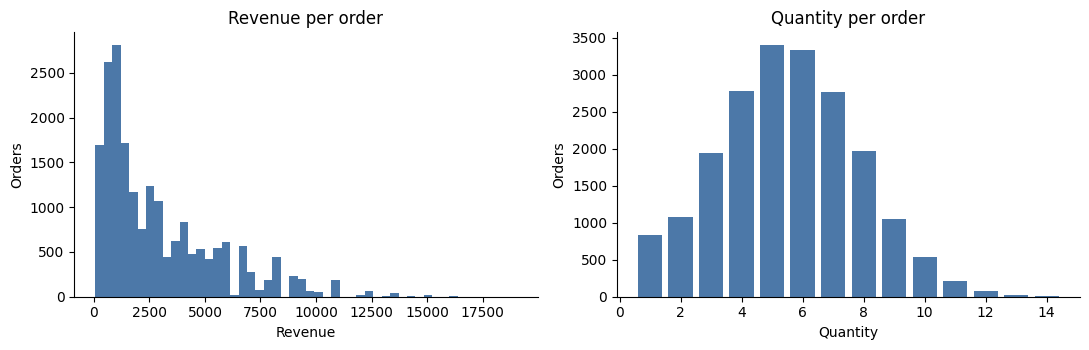

In [11]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
ax[0].hist(df["Revenue"], bins=50, color="#4C78A8")
ax[0].set(title="Revenue per order", xlabel="Revenue", ylabel="Orders")
q = df["Quantity"].value_counts().sort_index()
ax[1].bar(q.index, q.values, color="#4C78A8")
ax[1].set(title="Quantity per order", xlabel="Quantity", ylabel="Orders")
plt.tight_layout()
plt.show()

## 6. Phân bố theo nhóm

In [12]:
def dist(frame, col):
    out = frame[col].value_counts(dropna=True).rename("count").to_frame()
    out["pct"] = (out["count"] / out["count"].sum() * 100).round(1)
    return out

customers = df.drop_duplicates("CustomerID")   # customer-level attributes

print("Order-level distributions")
for col in ["OrderStatus", "ShippingType", "PaymentType", "ProductType"]:
    print(f"\n[{col}]")
    print(dist(df, col).to_string())

print("\nCustomer-level distributions (one row per customer)")
for col in ["Gender", "AgeGroup", "Loyalty"]:
    print(f"\n[{col}]")
    print(dist(customers, col).to_string())

Order-level distributions

[OrderStatus]
             count   pct
OrderStatus             
Completed    13435 67.20
Cancelled     6565 32.80

[ShippingType]
              count   pct
ShippingType             
Standard      10047 50.20
Express        4972 24.90
Economy        2973 14.90
Same-Day       2008 10.00

[PaymentType]
                  count   pct
PaymentType                  
Credit Card        6945 34.70
E-Wallet           5052 25.30
Debit Card         4031 20.20
Bank Transfer      2019 10.10
Cash on Delivery   1953  9.80

[ProductType]
             count   pct
ProductType             
Smartphone    6027 30.10
Tablet        4124 20.60
Smartwatch    3941 19.70
Laptop        3890 19.40
Headphones    2018 10.10

Customer-level distributions (one row per customer)

[Gender]
        count   pct
Gender             
Female   6366 52.50
Male     5770 47.50

[AgeGroup]
             count   pct
AgeGroup                
Adult         3720 30.70
Middle Age    3103 25.60
Young Adult   213

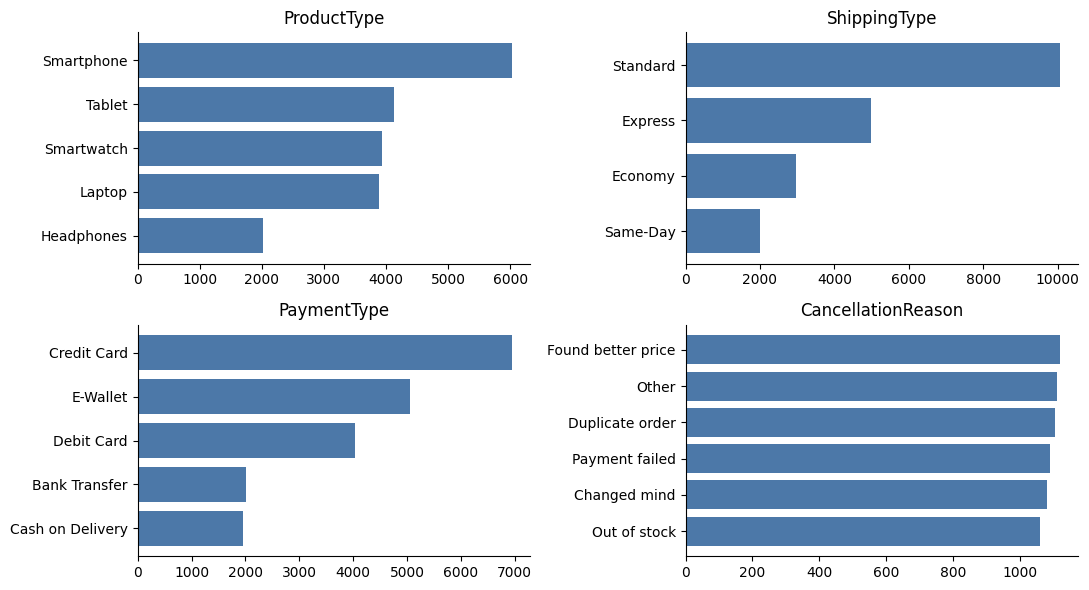

In [13]:
fig, ax = plt.subplots(2, 2, figsize=(11, 6))
for a, col in zip(ax.ravel(), ["ProductType", "ShippingType", "PaymentType", "CancellationReason"]):
    s = df[col].value_counts()
    a.barh(s.index[::-1], s.values[::-1], color="#4C78A8")
    a.set_title(col)
plt.tight_layout()
plt.show()

## 7. Phân tích theo thời gian

In [14]:
start, end = df["OrderDate"].min(), df["OrderDate"].max()
all_days = pd.date_range(start, end, freq="D")
days_with_orders = df["OrderDate"].dt.normalize().nunique()
print(f"Date range           : {start:%Y-%m-%d} to {end:%Y-%m-%d} ({len(all_days)} days)")
print(f"Days with >= 1 order : {days_with_orders} ({days_with_orders / len(all_days):.0%} of the range)")

daily = df.groupby(df["OrderDate"].dt.normalize()).size().reindex(all_days, fill_value=0)
print(f"Orders per day       : mean {daily.mean():.1f}, min {daily.min()}, max {daily.max()}")

Date range           : 2023-09-01 to 2024-09-23 (389 days)
Days with >= 1 order : 389 (100% of the range)
Orders per day       : mean 51.4, min 2, max 91


In [15]:
monthly = (
    df.assign(Month=df["OrderDate"].dt.to_period("M"))
      .groupby("Month")
      .agg(orders=("OrderID", "count"), revenue=("Revenue", "sum"), profit=("Profit", "sum"),
           cancel_rate_pct=("OrderStatus", lambda s: (s == "Cancelled").mean() * 100))
)
monthly["margin %"] = monthly["profit"] / monthly["revenue"] * 100
monthly["days covered"] = df.groupby(df["OrderDate"].dt.to_period("M"))["OrderDate"].agg(lambda s: s.dt.normalize().nunique())
monthly["orders MoM %"] = monthly["orders"].pct_change() * 100
monthly

,orders,revenue,profit,cancel_rate_pct,margin %,days covered,orders MoM %
Month,,,,,,,
2023-09,190,"545,755.31","430,822.84",35.26,78.94,30,NaN
2023-10,911,"2,647,425.53","2,082,648.60",33.59,78.67,31,379.47
2023-11,797,"2,382,523.13","1,870,801.86",34.00,78.52,30,-12.51
2023-12,800,"2,424,440.33","1,902,036.49",36.12,78.45,31,0.38
2024-01,2049,"6,140,339.90","4,834,230.08",30.89,78.73,31,156.12
2024-02,1818,"5,256,116.80","4,144,370.23",33.00,78.85,29,-11.27
2024-03,1957,"5,915,325.26","4,645,135.00",33.27,78.53,31,7.65
2024-04,1932,"5,574,026.31","4,400,376.96",32.45,78.94,30,-1.28
2024-05,2048,"5,961,670.55","4,694,784.39",33.11,78.75,31,6.00


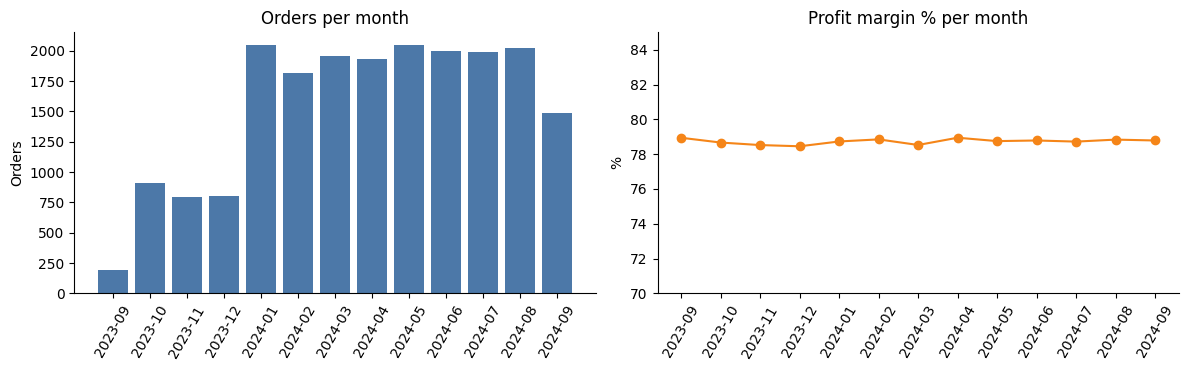

In [16]:
fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
x = monthly.index.astype(str)
ax[0].bar(x, monthly["orders"], color="#4C78A8")
ax[0].set(title="Orders per month", ylabel="Orders")
ax[0].tick_params(axis="x", rotation=60)
ax[1].plot(x, monthly["margin %"], marker="o", color="#F58518")
ax[1].set(title="Profit margin % per month", ylabel="%", ylim=(70, 85))
ax[1].tick_params(axis="x", rotation=60)
plt.tight_layout()
plt.show()

Tháng cuối chỉ có dữ liệu đến ngày 23, nên số đơn và doanh thu của tháng này thấp hơn thực tế. Cần ghi chú khi đọc các chỉ số so sánh với tháng trước (MoM).

## 8. Hành vi khách hàng

In [17]:
orders_per_customer = df.groupby("CustomerID").size()
dist_oc = orders_per_customer.value_counts().sort_index().rename("customers").to_frame()
dist_oc["pct"] = (dist_oc["customers"] / dist_oc["customers"].sum() * 100).round(1)
print(dist_oc.to_string())

repeat_ids = orders_per_customer[orders_per_customer > 1].index
rev_by_cust = df.groupby("CustomerID")["Revenue"].sum().sort_values(ascending=False)
top20 = rev_by_cust.head(int(len(rev_by_cust) * 0.2)).sum() / rev_by_cust.sum()

print(f"\nCustomers            : {len(orders_per_customer):,}")
print(f"Repeat customers     : {len(repeat_ids):,} ({len(repeat_ids) / len(orders_per_customer):.1%})")
print(f"Revenue from repeat  : {df.loc[df['CustomerID'].isin(repeat_ids), 'Revenue'].sum() / df['Revenue'].sum():.1%}")
print(f"Top 20% customers    : {top20:.1%} of revenue")

   customers   pct
1       7012 57.80
2       3162 26.10
3       1325 10.90
4        504  4.20
5        126  1.00
6          6  0.00
7          1  0.00

Customers            : 12,136
Repeat customers     : 5,124 (42.2%)
Revenue from repeat  : 64.7%
Top 20% customers    : 48.7% of revenue


In [18]:
loyalty = (
    df.groupby("Loyalty")
      .agg(customers=("CustomerID", "nunique"), orders=("OrderID", "count"), revenue=("Revenue", "sum"))
)
loyalty["orders per customer"] = loyalty["orders"] / loyalty["customers"]
loyalty["revenue per customer"] = loyalty["revenue"] / loyalty["customers"]
loyalty

,customers,orders,revenue,orders per customer,revenue per customer
Loyalty,,,,,
No,3692,6086,"17,612,997.11",1.65,"4,770.58"
Yes,8444,13914,"41,095,775.14",1.65,"4,866.86"


## 9. Sản phẩm

In [19]:
by_type = (
    df.groupby("ProductType")
      .agg(orders=("OrderID", "count"), units=("Quantity", "sum"), revenue=("Revenue", "sum"), profit=("Profit", "sum"))
)
by_type["revenue %"] = by_type["revenue"] / by_type["revenue"].sum() * 100
by_type["margin %"] = by_type["profit"] / by_type["revenue"] * 100
by_type["avg order value"] = by_type["revenue"] / by_type["orders"]
by_type.sort_values("revenue", ascending=False)

,orders,units,revenue,profit,revenue %,margin %,avg order value
ProductType,,,,,,,
Laptop,3890,21559,"23,689,235.92","17,464,920.23",40.35,73.73,"6,089.78"
Smartphone,6027,33502,"21,979,490.63","17,881,836.98",37.44,81.36,"3,646.84"
Tablet,4124,22747,"7,012,054.33","5,340,727.77",11.94,76.16,"1,700.30"
Smartwatch,3941,21449,"4,384,363.32","4,015,425.68",7.47,91.59,"1,112.50"
Headphones,2018,11108,"1,643,628.05","1,524,946.04",2.80,92.78,814.48


SKUs needed to reach 80% of revenue: 7 of 16


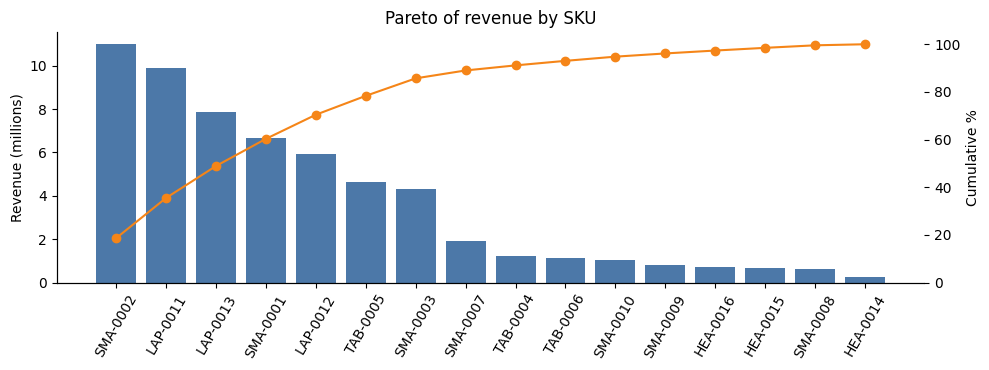

In [20]:
sku = df.groupby("SKU")["Revenue"].sum().sort_values(ascending=False)
cum = sku.cumsum() / sku.sum() * 100
print(f"SKUs needed to reach 80% of revenue: {(cum < 80).sum() + 1} of {len(sku)}")

fig, ax = plt.subplots(figsize=(10, 3.8))
ax.bar(sku.index, sku.values / 1e6, color="#4C78A8")
ax.set(ylabel="Revenue (millions)", title="Pareto of revenue by SKU")
ax.tick_params(axis="x", rotation=60)
ax2 = ax.twinx()
ax2.plot(sku.index, cum.values, color="#F58518", marker="o")
ax2.set(ylabel="Cumulative %", ylim=(0, 105))
ax2.spines["top"].set_visible(False)
plt.tight_layout()
plt.show()

## 10. Hủy đơn và đánh giá

In [21]:
canc = df.assign(is_cancelled=df["OrderStatus"].eq("Cancelled"))
for col in ["ProductType", "ShippingType", "PaymentType"]:
    t = (canc.groupby(col)["is_cancelled"].mean() * 100).round(1).sort_values(ascending=False)
    print(f"Cancellation rate % by {col}:", t.to_dict())

reasons = df["CancellationReason"].value_counts(normalize=True).mul(100).round(1)
print("\nCancellation reasons % of cancelled orders:", reasons.to_dict())
print(f"Revenue lost to cancellation: {df.loc[canc['is_cancelled'], 'Revenue'].sum() / 1e6:.2f}M "
      f"({df.loc[canc['is_cancelled'], 'Revenue'].sum() / df['Revenue'].sum():.1%} of total revenue)")

Cancellation rate % by ProductType: {'Tablet': 34.4, 'Laptop': 33.7, 'Smartphone': 32.5, 'Smartwatch': 32.0, 'Headphones': 30.5}
Cancellation rate % by ShippingType: {'Same-Day': 33.7, 'Economy': 33.3, 'Standard': 32.6, 'Express': 32.5}
Cancellation rate % by PaymentType: {'Bank Transfer': 34.3, 'Cash on Delivery': 33.8, 'Credit Card': 33.4, 'Debit Card': 32.0, 'E-Wallet': 31.7}

Cancellation reasons % of cancelled orders: {'Found better price': 17.0, 'Other': 16.9, 'Duplicate order': 16.8, 'Payment failed': 16.6, 'Changed mind': 16.5, 'Out of stock': 16.2}
Revenue lost to cancellation: 19.52M (33.2% of total revenue)


In [22]:
rating = df["Rating"].dropna().astype(int)
print("Rating distribution % (completed orders):", (rating.value_counts(normalize=True).sort_index() * 100).round(1).to_dict())
print(f"Rating 1-2: {(rating <= 2).mean():.1%} | 3: {(rating == 3).mean():.1%} | 4-5: {(rating >= 4).mean():.1%}")
print("Average rating by ProductType:", df.groupby("ProductType")["Rating"].mean().round(2).to_dict())

Rating distribution % (completed orders): {1: 11.6, 2: 17.4, 3: 32.3, 4: 23.8, 5: 14.8}
Rating 1-2: 29.0% | 3: 32.3% | 4-5: 38.6%
Average rating by ProductType: {'Headphones': 3.15, 'Laptop': 3.13, 'Smartphone': 3.11, 'Smartwatch': 3.15, 'Tablet': 3.12}


## 11. Đối soát với dashboard Power BI

So sánh các chỉ số tính bằng pandas với giá trị mà các measure DAX trả về khi không áp dụng slicer nào.

In [23]:
completed = df["OrderStatus"].eq("Completed")
n_cust = df["CustomerID"].nunique()

computed = {
    "Total Orders": df["OrderID"].nunique(),
    "Total Customers": n_cust,
    "Total Revenue": df["Revenue"].sum(),
    "Total Cost": df["Cost"].sum(),
    "Total Profit": df["Profit"].sum(),
    "Profit Margin %": df["Profit"].sum() / df["Revenue"].sum() * 100,
    "Total Units Sold": df["Quantity"].sum(),
    "Completed Orders": int(completed.sum()),
    "Cancelled Orders": int((~completed).sum()),
    "Cancellation Rate %": (~completed).mean() * 100,
    "Average Rating": df.loc[completed, "Rating"].mean(),
    "Repeat Customers": int((orders_per_customer > 1).sum()),
    "Frequency": len(df) / n_cust,
    "Revenue per Customer": df["Revenue"].sum() / n_cust,
}
dashboard = {
    "Total Orders": 20000, "Total Customers": 12136,
    "Total Revenue": 58708772.25, "Total Cost": 12480915.55, "Total Profit": 46227856.70,
    "Profit Margin %": 78.74, "Total Units Sold": 110365,
    "Completed Orders": 13435, "Cancelled Orders": 6565, "Cancellation Rate %": 32.83,
    "Average Rating": 3.13, "Repeat Customers": 5124, "Frequency": 1.65, "Revenue per Customer": 4837.57,
}
recon = pd.DataFrame({"pandas": computed, "dashboard": dashboard})
# dashboard values are rounded to 2 decimals, so allow a 0.006 absolute tolerance
recon["match"] = (recon["pandas"] - recon["dashboard"]).abs() <= 0.006
recon

,pandas,dashboard,match
Total Orders,"20,000.00","20,000.00",True
Total Customers,"12,136.00","12,136.00",True
Total Revenue,"58,708,772.25","58,708,772.25",True
Total Cost,"12,480,915.55","12,480,915.55",True
Total Profit,"46,227,856.70","46,227,856.70",True
Profit Margin %,78.74,78.74,True
Total Units Sold,"110,365.00","110,365.00",True
Completed Orders,"13,435.00","13,435.00",True
Cancelled Orders,"6,565.00","6,565.00",True
Cancellation Rate %,32.82,32.83,True


## 12. Kết luận

- Bộ dữ liệu sạch và nhất quán, đủ điều kiện để tách bảng fact/dimension trong Power Query mà không cần loại dòng hay điền giá trị thiếu.
- Các điểm cần lưu ý khi phân tích (doanh thu gồm đơn bị hủy, tháng cuối chưa đủ ngày, nhãn `Loyalty` có sẵn, tiền tố SKU) được tổng hợp trong [`eda_findings.md`](./eda_findings.md).